# African SLM Tool Calling Hackathon: starter notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aims-ai-research-foundations/airf-slm-tool-calling-hackathon/blob/main/starter_notebook.ipynb)

Three approaches with **Gemma 3 270M**, each scored by exact-match accuracy:

1. **Zero-shot prompting**: no training.
2. **Fine-tuning** on 1,000 training examples.
3. **More training data**: the same fine-tuning on 3,000 examples.

Runtime: about 20 minutes on a Colab T4 GPU (*Runtime → Change runtime type → T4 GPU*).

# Install Libraries

In [1]:
import importlib.util
import subprocess
import sys

# Ensure torchao is installed and upgraded to a version > 0.16.0
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "torchao"])

missing = [package for package in ("peft", "accelerate") if importlib.util.find_spec(package) is None]
if missing:  # Colab already has torch and transformers
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("installed:", missing or "nothing needed (torchao upgraded)")

installed: nothing needed (torchao upgraded)


# Environment and Imports

In [2]:
import json
import math
import os
import random
import re
import time
import urllib.request
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer

SEED = 0
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE, DTYPE = "cuda", torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32
elif torch.backends.mps.is_available():
    DEVICE, DTYPE = "mps", torch.bfloat16
else:
    DEVICE, DTYPE = "cpu", torch.float32
print("device:", DEVICE)

# Charts: one fixed colour per approach.
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3de", "axes.axisbelow": True, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})

W1110 05:56:58.413000 1035 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1110 05:56:58.479000 1035 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


device: cuda


Gemma needs a Hugging Face token from an account that has accepted the
[Gemma licence](https://huggingface.co/google/gemma-3-270m-it). On Colab, add it to *Secrets* as `HF_TOKEN`.

In [3]:
try:
    from google.colab import userdata
    from huggingface_hub import login

    login(userdata.get("HF_TOKEN"))
except ImportError:  # not on Colab: use `huggingface-cli login` or the HF_TOKEN variable
    pass

The data is downloaded from the [hackathon repository](https://github.com/aims-ai-research-foundations/airf-slm-tool-calling-hackathon) into `data/`.

In [4]:
REPO = "https://raw.githubusercontent.com/aims-ai-research-foundations/airf-slm-tool-calling-hackathon/main/data"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
for name in ("tools.json", "train.jsonl", "dev.jsonl"):  # always the latest files from the repository
    urllib.request.urlretrieve(f"{REPO}/{name}", DATA_DIR / name)


def read_jsonl(path: Path) -> list[dict]:
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


def answer_of(row: dict):
    """A training row's answer: its tool_calls, or its tool and parameters."""
    return row["tool_calls"] if "tool_calls" in row else {"tool": row["tool"], "parameters": row["parameters"]}


def calls_of(answer) -> list[dict]:
    return answer if isinstance(answer, list) else [answer]


tools = {tool["name"]: tool for tool in json.loads((DATA_DIR / "tools.json").read_text())}
train = [dict(row, answer=answer_of(row)) for row in read_jsonl(DATA_DIR / "train.jsonl")]
dev = read_jsonl(DATA_DIR / "dev.jsonl")
print(f"{len(tools)} tools · {len(train):,} train · {len(dev):,} dev")

10 tools · 15,000 train · 2,000 dev


# Exploratory Data Analysis

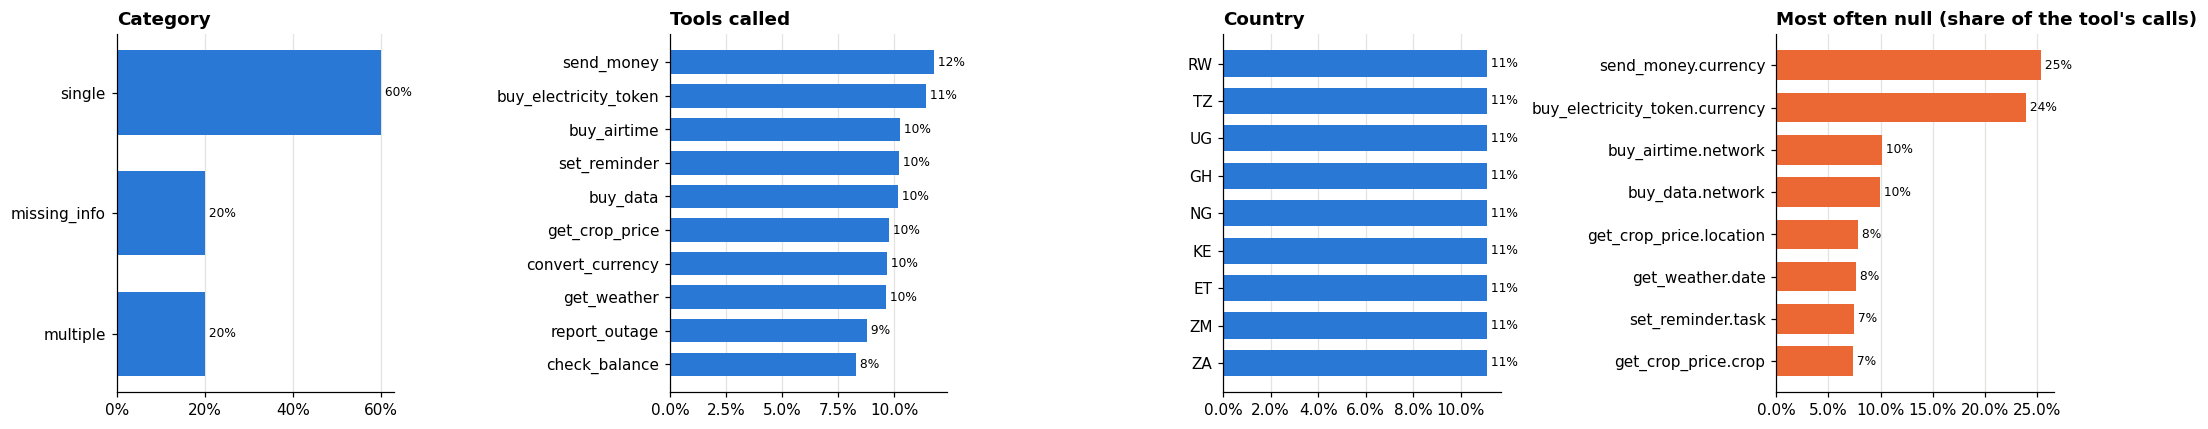

In [5]:
meta = pd.DataFrame([ex["meta"] for ex in train])
per_tool = Counter(call["tool"] for ex in train for call in calls_of(ex["answer"]))
nulls = Counter(param for params in meta["null_params"] for param in params)
panels = [
    ("Category", meta["category"].value_counts(normalize=True).sort_values()),
    ("Tools called", (pd.Series(per_tool) / sum(per_tool.values())).sort_values()),
    ("Country", meta["country"].value_counts(normalize=True).sort_values()),
    ("Most often null (share of the tool's calls)", pd.Series({p: n / per_tool[p.split(".")[0]] for p, n in nulls.items()}).sort_values().tail(8)),
]

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, (title, values) in zip(axes, panels):
    ax.barh(values.index, values.values, color=ORANGE if "null" in title else BLUE, height=0.7)
    for y, v in enumerate(values.values):
        ax.text(v, y, f" {v:.0%}", va="center", fontsize=8)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [6]:
for category in ("single", "missing_info", "multiple"):
    ex = next(ex for ex in train if ex["meta"]["category"] == category)
    print(f"[{category}] {ex['request']}\n  -> {json.dumps(ex['answer'], ensure_ascii=False)}\n")

[single] Quick one: my cousin abroad sent me two hundred Ghana cedis. How much is that in EUR? Cheers.
  -> {"tool": "convert_currency", "parameters": {"amount": 200, "from_currency": "GHS", "to_currency": "EUR"}}

[missing_info] 2k Rwandan francs airtime for +250732453875
  -> {"tool": "buy_airtime", "parameters": {"phone": "+250732453875", "amount": 2000, "network": null}}

[multiple] don't let me forget to pick up the kids from school on tuesday at 7:15am. also, what is kes 20k worth in ugandan shillings?
  -> [{"tool": "set_reminder", "parameters": {"task": "pick up the kids from school", "date": "tuesday", "time": "07:15"}}, {"tool": "convert_currency", "parameters": {"amount": 20000, "from_currency": "KES", "to_currency": "UGX"}}]



In [7]:
print("VARIABLES DISPONIBLES :")

for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "train", "data", "dataset", "tool", "valid", "dev", "test"
    ]):
        try:
            obj = globals()[name]
            print(f"{name}: {type(obj).__name__}", end="")
            if hasattr(obj, "__len__"):
                print(f" | Taille: {len(obj)}")
            else:
                print()
        except:
            pass

VARIABLES DISPONIBLES :
DATA_DIR: PosixPath
DEVICE: str | Taille: 4
dev: list | Taille: 2000
per_tool: Counter | Taille: 10
tools: dict | Taille: 10
train: list | Taille: 15000
userdata: module


In [8]:
import random
import copy
from collections import Counter

random.seed(42)

# Reconstruire les données d'entraînement
train_pool = copy.deepcopy(train)

# Vérifier la structure
print("Nombre d'exemples :", len(train_pool))
print("\nPremier exemple :")
print(train_pool[0])

print("\nRépartition des outils :")
print(per_tool)

print("\nDéfinitions des outils :")
print(tools)

Nombre d'exemples : 15000

Premier exemple :
{'id': 'train-00001', 'request': "don't let me forget to pick up the kids from school on tuesday at 7:15am. also, what is kes 20k worth in ugandan shillings?", 'tools': ['get_weather', 'buy_electricity_token', 'buy_data', 'set_reminder', 'convert_currency', 'send_money'], 'tool_calls': [{'tool': 'set_reminder', 'parameters': {'task': 'pick up the kids from school', 'date': 'tuesday', 'time': '07:15'}}, {'tool': 'convert_currency', 'parameters': {'amount': 20000, 'from_currency': 'KES', 'to_currency': 'UGX'}}], 'meta': {'country': 'KE', 'city': 'Mombasa', 'style': 'chat', 'category': 'multiple', 'kind': 'different_tools', 'n_calls': 2, 'null_params': []}, 'answer': [{'tool': 'set_reminder', 'parameters': {'task': 'pick up the kids from school', 'date': 'tuesday', 'time': '07:15'}}, {'tool': 'convert_currency', 'parameters': {'amount': 20000, 'from_currency': 'KES', 'to_currency': 'UGX'}}]}

Répartition des outils :
Counter({'send_money': 2156

In [9]:

import copy
import random
from collections import Counter

random.seed(42)

# ============================================================
# 1. CONFIGURATION
# ============================================================

TARGET_SIZE = 30000
N_SYNTHETIC = TARGET_SIZE - len(train)

prefixes = [
    "Please help me with this request: ",
    "Can you take care of this for me? ",
    "I need your assistance with this: ",
    "Could you please process this request? ",
    "Here is what I would like you to do: ",
    "Please handle the following: ",
    "I have a request: ",
    "Can you help me with the following? ",
    "I would like you to do this: ",
    "Kindly assist me with this: ",
    "Would you please help me with this? "
]

suffixes = [
    "", " Please.", " Thanks.",
    " Thank you.", " I would appreciate your help."
]

# ============================================================
# 2. GENERATION
# ============================================================

synthetic_examples = []

for i in range(N_SYNTHETIC):

    original = copy.deepcopy(train[i % len(train)])
    example = copy.deepcopy(original)

    request = original.get("request")

    if not isinstance(request, str) or not request.strip():
        continue

    example["request"] = (
        random.choice(prefixes)
        + request.strip()
        + random.choice(suffixes)
    )

    # Identifiant synthétique unique
    example["id"] = f"synthetic-{i+1:05d}"

    # Conserver exactement les clés et les labels d'origine
    for key in original:
        if key != "id" and key != "request":
            example[key] = copy.deepcopy(original[key])

    synthetic_examples.append(example)

# ============================================================
# 3. DATASET FINAL
# ============================================================

augmented_train_pool = (
    copy.deepcopy(train) + synthetic_examples
)

random.shuffle(augmented_train_pool)

# ============================================================
# 4. CONTROLES
# ============================================================

print("=" * 55)
print("AUGMENTATION TERMINEE")
print("=" * 55)

print("Originaux :", len(train))
print("Synthétiques :", len(synthetic_examples))
print("Total :", len(augmented_train_pool))

assert len(augmented_train_pool) == TARGET_SIZE

# Vérification de la conservation des réponses
for i in range(min(100, len(synthetic_examples))):
    source = train[i]
    generated = synthetic_examples[i]

    assert generated["answer"] == source["answer"]

print("\n100 premières réponses vérifiées.")

print("\nRépartition des catégories :")
print(Counter(
    x.get("meta", {}).get("category", "unknown")
    for x in augmented_train_pool
))

print("\nDataset prêt.")


AUGMENTATION TERMINEE
Originaux : 15000
Synthétiques : 15000
Total : 30000

100 premières réponses vérifiées.

Répartition des catégories :
Counter({'single': 18000, 'missing_info': 6000, 'multiple': 6000})

Dataset prêt.


- 60% of requests need one call with every value given, 20% leave a value out (`null`), 20% need several calls.
- Tools and countries are evenly spread.
- The value most often missing is the currency: it is only given when the request writes it ("5k" alone has none).

# Gemma 270M Zero-Shot Prompting

The prompt is a one-line instruction, a signature for each offered tool, and the request. The model answers with
a JSON **list** of calls (a list of one call scores the same as the call itself). We score on **300 training
examples held out for validation**, 100 per category.

In [10]:
MODEL_NAME = "google/gemma-3-1B-it"
INSTRUCTION = "Reply with a JSON list of the tool calls for the request, with null for values not given.\nTools:\n"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "left"


def build_prompt(example: dict) -> str:
    signatures = [f"{name}({', '.join(f'{p}: {t}' for p, t in tools[name]['parameters'].items())})" for name in example["tools"]]
    messages = [{"role": "system", "content": INSTRUCTION + "\n".join(signatures)}, {"role": "user", "content": example["request"]}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)


def target_text(answer) -> str:
    return json.dumps(calls_of(answer), ensure_ascii=False) + "<end_of_turn>"


by_category = defaultdict(list)
for ex in train:
    by_category[ex["meta"]["category"]].append(ex)
validation = [ex for group in by_category.values() for ex in random.Random(SEED).sample(group, 100)]
held = {ex["id"] for ex in validation}
train_pool = [ex for ex in train if ex["id"] not in held]

print(build_prompt(validation[0]) + target_text(validation[0]["answer"]))

config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

<bos><start_of_turn>user
Reply with a JSON list of the tool calls for the request, with null for values not given.
Tools:
convert_currency(amount: number, from_currency: string, to_currency: string)
get_weather(location: string, date: string)
buy_airtime(phone: string, amount: number, network: string)
buy_electricity_token(meter_number: string, amount: number, currency: string)
send_money(recipient: string, amount: number, currency: string, provider: string)
report_outage(location: string)

Good afternoon. Check the forecast for Kasama on the 4th of Apr and buy a K500 electricity token for meter 43120234071. Thank you.<end_of_turn>
<start_of_turn>model
[{"tool": "get_weather", "parameters": {"location": "Kasama", "date": "4 April"}}, {"tool": "buy_electricity_token", "parameters": {"meter_number": "43120234071", "amount": 500, "currency": "ZMW"}}]<end_of_turn>


In [11]:
def normalise(value):
    """As the official scorer: numbers as floats; text lowercased without punctuation."""
    if isinstance(value, (int, float)) and not isinstance(value, bool):
        return float(value)
    if isinstance(value, str):
        return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", "", value.lower())).strip()
    return value


def canonical(answer):
    """A comparable form of an answer, with null parameters dropped; None if it is not a call or a list of calls."""
    try:
        return tuple((c["tool"], tuple(sorted((k, normalise(v)) for k, v in c["parameters"].items() if v is not None)))
                     for c in calls_of(answer))
    except (TypeError, KeyError, AttributeError):
        return None


def score(predictions: dict) -> dict:
    """Exact match on the validation set, overall and per category."""
    hits = defaultdict(list)
    for ex in validation:
        hits[ex["meta"]["category"]].append(canonical(predictions.get(ex["id"])) == canonical(ex["answer"]))
    return {"overall": np.mean(sum(hits.values(), []))} | {k: np.mean(hits[k]) for k in ("single", "missing_info", "multiple")}


def parse(text: str):
    """The JSON answer in the model's text, or None."""
    text = text.split("<end_of_turn>")[0]
    starts = [i for i in (text.find("["), text.find("{")) if i >= 0]
    try:
        value = json.JSONDecoder().raw_decode(text, min(starts))[0] if starts else None
    except json.JSONDecodeError:
        return None
    return value[0] if isinstance(value, list) and len(value) == 1 else value


@torch.no_grad()
def predict(model, examples: list[dict], batch_size: int = 32) -> dict:
    """Greedy answers, parsed: {id: answer or None}."""
    model.eval()
    order = sorted(examples, key=lambda ex: len(build_prompt(ex)))  # similar lengths batch together
    stop = [tokenizer.eos_token_id, tokenizer.convert_tokens_to_ids("<end_of_turn>")]
    out = {}
    for i in range(0, len(order), batch_size):
        batch = order[i:i + batch_size]
        inputs = tokenizer([build_prompt(ex) for ex in batch], return_tensors="pt", padding=True, add_special_tokens=False).to(DEVICE)
        tokens = model.generate(**inputs, max_new_tokens=200, do_sample=False, eos_token_id=stop, pad_token_id=tokenizer.pad_token_id)
        for ex, seq in zip(batch, tokens[:, inputs["input_ids"].shape[1]:]):
            out[ex["id"]] = parse(tokenizer.decode(seq, skip_special_tokens=False))
    return out

In [12]:
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE, attn_implementation="eager").to(DEVICE)
zero_shot = predict(model, validation)
results = {"1. Zero-shot": score(zero_shot)}

ex = validation[0]
print("Request: ", ex["request"])
print("Expected:", json.dumps(ex["answer"], ensure_ascii=False))
print("Got:     ", zero_shot[ex["id"]])
pd.DataFrame(results).T.round(3)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.00GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Request:  Good afternoon. Check the forecast for Kasama on the 4th of Apr and buy a K500 electricity token for meter 43120234071. Thank you.
Expected: [{"tool": "get_weather", "parameters": {"location": "Kasama", "date": "4 April"}}, {"tool": "buy_electricity_token", "parameters": {"meter_number": "43120234071", "amount": 500, "currency": "ZMW"}}]
Got:      None


,overall,single,missing_info,multiple
1. Zero-shot,0.0,0.0,0.0,0.0


Without training, Gemma 3 270M does not produce correct tool calls: its exact-match accuracy is close to zero.

# Gemma 270M Fine-Tuning

LoRA (rank 16 on every linear layer), learning rate 2e-4, one epoch on **1,000** training examples. The loss is
computed on the answer tokens only.

In [13]:
import gc
import time
import math
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import (
    AutoModelForCausalLM,
    BitsAndBytesConfig
)
from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training
)

COLORS = {
    "1. Zero-shot": MUTED,
    "2. Fine-tuned (1,000)": ORANGE,
    "3. Fine-tuned (3,000)": BLUE
}

def fine_tune(
    examples: list[dict],
    lr: float = 2e-4,
    batch_tokens: int = 1024
):
    """Gemma 3 1B - QLoRA 4 bits - GPU T4."""

    start = time.time()
    print("Chargement de Gemma 3 1B en QLoRA 4 bits...")

    # 1. Quantification 4 bits
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True
    )

    # 2. Chargement du modèle quantifié
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        quantization_config=bnb_config,
        device_map={"": 0},
        attn_implementation="eager"
    )

    # 3. Préparation QLoRA
    model.config.use_cache = False
    model = prepare_model_for_kbit_training(
        model,
        use_gradient_checkpointing=False
    )

    # 4. Adaptateurs LoRA
    lora_config = LoraConfig(
        task_type="CAUSAL_LM",
        r=16,
        lora_alpha=32,
        lora_dropout=0.05,
        target_modules="all-linear",
        bias="none"
    )

    model = get_peft_model(model, lora_config)
    model.print_trainable_parameters()

    print("\nPréparation des données...")

    # 5. Préparation des séquences
    rows = []
    for ex in examples:
        prompt = tokenizer(
            build_prompt(ex),
            add_special_tokens=False
        )["input_ids"]

        answer = tokenizer(
            target_text(ex["answer"]),
            add_special_tokens=False
        )["input_ids"]

        rows.append((
            prompt + answer,
            [-100] * len(prompt) + answer
        ))

    random.Random(SEED).shuffle(rows)
    rows.sort(key=lambda row: len(row[0]) // 32)

    # 6. Construction des lots
    batches = []
    batch = []
    current_tokens = 0

    for row in rows:
        row_tokens = len(row[0])
        if batch and current_tokens + row_tokens > batch_tokens:
            batches.append(batch)
            batch = []
            current_tokens = 0
        batch.append(row)
        current_tokens += row_tokens

    if batch:
        batches.append(batch)

    random.Random(SEED).shuffle(batches)

    # 7. Optimisation
    trainable_params = [
        p for p in model.parameters() if p.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        trainable_params,
        lr=lr
    )

    schedule = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda s: min(1, (s + 1) / 10) *
        0.5 * (1 + math.cos(math.pi * s / len(batches)))
    )

    base = model.get_base_model()
    model.train()

    losses = []
    total_steps = len(batches)

    print(
        f"\nDébut : {len(examples):,} exemples | "
        f"{total_steps:,} étapes\n"
    )

    # 8. Entraînement avec progression
    progress = tqdm(
        enumerate(batches, 1),
        total=total_steps,
        desc="QLoRA Gemma 3 1B",
        unit="batch"
    )

    for step, batch in progress:
        width = max(len(ids) for ids, _ in batch)

        ids = torch.tensor(
            [
                [tokenizer.pad_token_id] * (width - len(i)) + i
                for i, _ in batch
            ],
            device="cuda"
        )

        labels = torch.tensor(
            [
                [-100] * (width - len(l)) + l
                for _, l in batch
            ],
            device="cuda"
        )

        mask = (ids != tokenizer.pad_token_id).long()

        hidden = base.model(
            input_ids=ids,
            attention_mask=mask,
            position_ids=(mask.cumsum(1) - 1).clamp(min=0)
        ).last_hidden_state

        targets = labels[:, 1:]
        keep = targets != -100

        logits = base.lm_head(
            hidden[:, :-1][keep]
        ).float()

        loss = torch.nn.functional.cross_entropy(
            logits,
            targets[keep]
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Loss invalide à l'étape {step}"
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            1.0
        )

        optimizer.step()
        schedule.step()
        optimizer.zero_grad(set_to_none=True)

        losses.append(loss.item())

        elapsed = (time.time() - start) / 60
        eta = (
            elapsed / step
        ) * (total_steps - step)

        avg_loss = np.mean(losses[-10:])

        progress.set_postfix({
            "Loss": f"{loss.item():.4f}",
            "Moyenne": f"{avg_loss:.4f}",
            "Temps": f"{elapsed:.1f} min",
            "ETA": f" {eta:.1f} min"
        })

        del hidden, logits, loss, ids, labels, mask

    # 9. Fin
    model.config.use_cache = True
    elapsed_min = (time.time() - start) / 60

    print("\nENTRAÎNEMENT TERMINÉ")
    print(f"Exemples : {len(examples):,}")
    print(f"Étapes : {total_steps:,}")
    print(f"Durée : {elapsed_min:.2f} minutes")
    print(f"Loss finale : {losses[-1]:.5f}")

    return model, losses

def plot(losses: dict):
    """The training loss of each fine-tuning run, and the exact match of every approach so far."""
    fig, (loss_ax, score_ax) = plt.subplots(
        1,
        2,
        figsize=(16, 4.5),
        gridspec_kw={"width_ratios": [1, 1.5]}
    )

    for name, values in losses.items():
        loss_ax.plot(
            pd.Series(values).rolling(10, min_periods=1).mean(),
            color=COLORS[name],
            linewidth=2,
            label=name
        )
    loss_ax.set(
        title="Training loss",
        xlabel="step",
        ylabel="loss (log scale)",
        yscale="log"
    )
    loss_ax.legend()

    groups = ["overall", "single", "missing_info", "multiple"]
    width = 0.8 / len(results)

    for i, (name, values) in enumerate(results.items()):
        xs = np.arange(len(groups)) + (i - (len(results) - 1) / 2) * width
        heights = [values[g] for g in groups]

        score_ax.bar(
            xs,
            heights,
            width=width * 0.92,
            color=COLORS[name],
            label=name
        )
        for x, h in zip(xs, heights):
            score_ax.text(
                x,
                h + 0.01,
                f"{h:.0%}",
                ha="center",
                va="bottom",
                fontsize=8
            )

    score_ax.set_xticks(range(len(groups)), groups)
    score_ax.set(title="Exact match on validation", ylim=(0, 1.1))
    score_ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    score_ax.grid(axis="x", visible=False)
    score_ax.legend(loc="upper left", ncol=len(results))

    plt.tight_layout()
    plt.show()

Fine-tuning on 1,000 examples turns a model that cannot call tools into one that gets many simple requests right.

# Impact of Using More Training Data

The same fine-tuning on **3,000** examples. Set `MORE_DATA = len(train_pool)` to use all 14,700 (about 20 minutes
more on a T4).

In [14]:
%pip install -q -U bitsandbytes>=0.46.1

import gc
import torch
import bitsandbytes as bnb

# Libération de la mémoire GPU
if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

# Configuration
MORE_DATA = 28000
BATCH_TOKENS = 1024

print("=" * 55)
print("GEMMA 3 1B — QLoRA 4 BITS — GPU T4")
print("=" * 55)
print(f"Exemples : {MORE_DATA:,}")
print(f"Batch tokens : {BATCH_TOKENS}")
print(f"GPU : {torch.cuda.get_device_name(0)}")

# Entraînement
model, losses_28k = fine_tune(
    augmented_train_pool[:MORE_DATA],
    batch_tokens=BATCH_TOKENS
)

# Évaluation
results["QLoRA Fine-tuned (28,000)"] = score(
    predict(model, validation)
)

print("\nÉvaluation terminée.")
print(results["QLoRA Fine-tuned (28,000)"])

GEMMA 3 1B — QLoRA 4 BITS — GPU T4
Exemples : 28,000
Batch tokens : 1024
GPU : Tesla T4
Chargement de Gemma 3 1B en QLoRA 4 bits...


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

trainable params: 13,045,760 || all params: 1,012,931,712 || trainable%: 1.2879

Préparation des données...

Début : 28,000 exemples | 5,952 étapes



QLoRA Gemma 3 1B:   0%|          | 0/5952 [00:00<?, ?batch/s]


ENTRAÎNEMENT TERMINÉ
Exemples : 28,000
Étapes : 5,952
Durée : 65.78 minutes
Loss finale : 0.00000

Évaluation terminée.
{'overall': np.float64(1.0), 'single': np.float64(1.0), 'missing_info': np.float64(1.0), 'multiple': np.float64(1.0)}


More data reaches a lower loss and a much higher score in every category, most of all on requests with missing
values and with several calls.

The 3,000-example model writes a submission for the dev leaderboard:

In [15]:
predictions = predict(model, dev)
empty = {"tool": "", "parameters": {}}  # an unreadable answer still needs an entry (it scores as wrong)
Path("predictions.json").write_text(json.dumps({k: v if v is not None else empty for k, v in predictions.items()}, ensure_ascii=False))
with zipfile.ZipFile("submission.zip", "w") as archive:
    archive.write("predictions.json")
print(f"{len(predictions):,} predictions → submission.zip")

2,000 predictions → submission.zip


# Ideas to Go Further

- Try FunctionGemma 270M, which was pre-trained for function calling
- Fine-tune a larger model. Remember it must be ≤ 4B parameters
- Generate more synthetic data and use more quality data with hard-mined examples
- Knowledge distillation
- Few-shot prompting
- Self-consistency and inference-time strategies
- Test-time scaling

**It's your world... Try → Evaluate → Improve → Repeat**